<a href="https://colab.research.google.com/github/taehubhub-commits/Deeplearn_sittipan/blob/main/deeplearn_text.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Capstone — Build, Train & Report a Deep Learning Model

This is **your** project. Across the course you built — by hand, on toy numbers in
the sandbox — tensors, the training loop, CNNs, RNNs/LSTMs, regularization, and the
habit of reading loss curves. Now you put it all together on a **real dataset you
choose**, and you are judged on a **held-out test set** you only touch once.

Unlike the weekly labs, this notebook is **mostly scaffold**. It gives you the
boring-but-essential spine — `device`/seed setup, `train()` / `evaluate()` /
`plot_curves()`, and a one-shot test-evaluation cell — so you can spend your effort
on the part that matters: the **model** and the **experiments**. Everything marked
**🔧 TODO** is yours to fill in. The notebook will not learn anything until you do.

> **Runtime → Change runtime type → T4 GPU** before you start. Then run the setup
> cell and confirm it prints `cuda`.

---

## Choose your track

Pick **one** track below and uncomment its data-loading stub in Beat 3. All three
use a *real* public dataset and target a model family you already met in the course.
You are free to invent your own task instead (any real dataset + a model you train)
— these three are just well-scoped starting points.

| Track | Dataset (real, auto-downloaded) | Model you build | Beat this baseline |
|---|---|---|---|
| **A · Vision** | **CIFAR-10** — 60k 32×32 colour photos, 10 classes | a **CNN** (Conv → ReLU → Pool …) | majority class = **10%**; aim **> 65%** test accuracy |
| **B · Text** | **Names-by-language** — ~20k surnames, 18 languages (PyTorch's char-RNN dataset) | a char-level **LSTM** classifier | majority class (English) ≈ **27%**; aim **> 70%** |
| **C · Tabular** | **Penguins** — 344 rows, 7 features, 3 species (seaborn) | an **MLP** | majority class ≈ **44%**; aim **> 95%** |

Each track is sized to train in **under ~5 minutes on a T4**. The spine below is
**track-agnostic**: write your dataset loader and model so that `train_loader`,
`val_loader`, `test_loader`, and `model` exist, and the generic `train()` /
`evaluate()` helpers just work.

> **The one rule that defines this capstone:** *tune on validation, report on test.*
> Choose your model, learning rate, epochs, and regularization using the **validation**
> set. Touch the **test** set exactly **once**, at the very end, for the number you
> report. Peeking at test while tuning turns it into a second validation set and
> quietly inflates your result — the rubric checks for this.

## 1 · Setup, GPU check & the spine

Run this once. It imports everything, fixes the seed so your runs are reproducible
(the rubric expects a fixed seed), picks the GPU, and defines the **spine** you'll
reuse no matter which track you chose:

- `accuracy(logits, y)` — exact-match accuracy for a batch of logits.
- `train(...)` — the generic five-step training loop with a validation pass each
  epoch; returns the per-epoch `history`.
- `evaluate(...)` — a no-grad forward pass returning `(loss, accuracy)`.
- `plot_curves(history)` — train-vs-val loss and accuracy, the diagnostic you learned
  to read in the labs.

These are deliberately model-agnostic: they assume a classifier whose `model(x)`
returns class **logits** and whose loader yields `(x, y)` batches. That covers all
three tracks. (Doing a regression or a language model instead? Swap
`CrossEntropyLoss`/accuracy for MSE/perplexity — the loop shape is identical.)

In [1]:
import random
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn

# --- reproducibility: fix the seed so your reported numbers reproduce -------
SEED = 0
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# --- device: train on the GPU if Colab gave you one -------------------------
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)
if device == "cpu":
    print("WARNING: no GPU. Runtime -> Change runtime type -> T4 GPU, then re-run.")


@torch.no_grad()
def accuracy(logits, y):
    """Fraction correct for a batch of class logits vs integer labels."""
    return (logits.argmax(dim=-1) == y).float().mean().item()


@torch.no_grad()
def evaluate(model, loader, loss_fn):
    """One no-grad pass over `loader`; returns (mean loss, accuracy)."""
    model.eval()                                  # dropout off, BN uses running stats
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)         # same device as the model
        logits = model(x)
        total_loss += loss_fn(logits, y).item() * len(y)
        correct += (logits.argmax(dim=-1) == y).sum().item()
        n += len(y)
    return total_loss / n, correct / n


def train(model, train_loader, val_loader, *, epochs=10, lr=1e-3,
          weight_decay=0.0, loss_fn=None, max_grad_norm=None):
    """The five-step loop (forward, loss, zero_grad, backward, step) with a
    validation pass each epoch. Returns a per-epoch history dict."""
    model = model.to(device)                      # move the model once, before the loop
    loss_fn = loss_fn or nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(epochs):
        model.train()
        for x, y in train_loader:                 # the five steps, per batch
            x, y = x.to(device), y.to(device)     # data on the SAME device as the model
            logits = model(x)                     # 1. forward
            loss = loss_fn(logits, y)             # 2. loss
            optimizer.zero_grad()                 # 3. clear last batch's grads
            loss.backward()                       # 4. backprop
            if max_grad_norm is not None:         # clip for RNNs/LSTMs (Track B)
                nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)
            optimizer.step()                      # 5. update the weights

        tr_loss, tr_acc = evaluate(model, train_loader, loss_fn)
        va_loss, va_acc = evaluate(model, val_loader, loss_fn)
        history["train_loss"].append(tr_loss)
        history["val_loss"].append(va_loss)
        history["train_acc"].append(tr_acc)
        history["val_acc"].append(va_acc)
        print(f"epoch {epoch + 1:2d}/{epochs}  "
              f"train_loss={tr_loss:.3f} acc={tr_acc:.2%}  |  "
              f"val_loss={va_loss:.3f} acc={va_acc:.2%}")
    return history


def plot_curves(history):
    """Train vs. validation loss and accuracy — read the gap (labs L5/L11)."""
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
    ax1.plot(epochs, history["train_loss"], "-o", label="train")
    ax1.plot(epochs, history["val_loss"], "-o", label="val")
    ax1.set(xlabel="epoch", ylabel="loss", title="Loss")
    ax1.legend(); ax1.grid(alpha=0.3)
    ax2.plot(epochs, history["train_acc"], "-o", label="train")
    ax2.plot(epochs, history["val_acc"], "-o", label="val")
    ax2.set(xlabel="epoch", ylabel="accuracy", title="Accuracy")
    ax2.legend(); ax2.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


print("spine ready: accuracy(), evaluate(), train(), plot_curves()")

device: cuda
spine ready: accuracy(), evaluate(), train(), plot_curves()


## 2 · 🔧 Load your real dataset (with a train / val / **test** split)

**Uncomment exactly one block below** (your chosen track). Each one downloads a real
dataset over the internet (Colab has it), builds a model-agnostic train/val/test
split, and exposes the **same four names** the spine expects:

```
train_loader   val_loader   test_loader   classes
```

plus whatever your model needs (`in_features`, `vocab_size`, `n_classes`, …). Keeping
the interface identical across tracks is what lets the generic `train()` / `evaluate()`
helpers work unchanged.

> **🔧 Your turn — the split is the load-bearing part.** Carve out a **test** set and
> *do not look at it* until the final cell. Tune everything on **val**. Each stub
> below does a clean 3-way split with the fixed `SEED`; read it, and if you bring your
> own dataset, replicate that discipline (no overlap, no peeking).

In [ ]:
# # ============================================================================
# # TRACK A · VISION — CIFAR-10 (real 32x32 colour photos, 10 classes)
# # Build a CNN. This block is ACTIVE so the notebook runs end-to-end out of the
# # box; comment it out if you pick Track B or C.
# # ============================================================================
# from torch.utils.data import DataLoader, random_split, Subset
# from torchvision import datasets, transforms

# # What's real/messy: natural photos with backgrounds, lighting, and pose
# # variation. Some classes look alike (cat vs dog, automobile vs truck) -- your
# # confusion matrix later will show exactly which.
# norm = transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))
# train_tf = transforms.Compose([                 # augment ONLY the training set
#     transforms.RandomHorizontalFlip(),
#     transforms.RandomCrop(32, padding=4),
#     transforms.ToTensor(), norm,
# ])
# eval_tf = transforms.Compose([transforms.ToTensor(), norm])   # never augment val/test

# # CIFAR's official split is 50k train + 10k test. We hold the 10k test out
# # untouched, and carve a validation set off the training data.
# full_train = datasets.CIFAR10("./data", train=True, download=True, transform=train_tf)
# test_set = datasets.CIFAR10("./data", train=False, download=True, transform=eval_tf)

# # Subset to train fast on a T4 (~3-4 min). Use all 50k for a stronger result.
# SUBSET = 10000
# g = torch.Generator().manual_seed(SEED)
# idx = torch.randperm(len(full_train), generator=g)[:SUBSET].tolist()
# n_val = SUBSET // 5
# train_idx, val_idx = idx[n_val:], idx[:n_val]
# train_set = Subset(full_train, train_idx)
# # val must NOT be augmented -> point it at a non-augmented copy of the data
# val_base = datasets.CIFAR10("./data", train=True, download=True, transform=eval_tf)
# val_set = Subset(val_base, val_idx)

# batch_size = 128
# train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
# val_loader = DataLoader(val_set, batch_size=batch_size)
# test_loader = DataLoader(test_set, batch_size=batch_size)
# classes = full_train.classes                    # ['airplane', 'automobile', ...]
# print(f"train={len(train_set)} val={len(val_set)} test={len(test_set)} "
#       f"classes={len(classes)}")

In [3]:
# ============================================================================
# TRACK B · TEXT — Names-by-language (real surnames, 18 languages)
# Build a char-level LSTM classifier. UNCOMMENT this whole block to use it,
# and comment out Track A above.
# ============================================================================
import os, glob, unicodedata, string, zipfile, urllib.request
from torch.utils.data import DataLoader, TensorDataset, random_split
from torch.nn.utils.rnn import pad_sequence

# Real/messy: PyTorch's char-RNN dataset -- one .txt per language, one surname
# per line, accented characters, and very imbalanced classes (English/Russian
# dominate). Stable URL, ~2.8 MB.
URL = "https://download.pytorch.org/tutorial/data.zip"
if not os.path.exists("data/names"):
    urllib.request.urlretrieve(URL, "data.zip")
    with zipfile.ZipFile("data.zip") as z:
        z.extractall(".")

all_letters = string.ascii_letters + " .,;'"
stoi = {c: i + 1 for i, c in enumerate(all_letters)}   # 0 reserved for <pad>
vocab_size = len(stoi) + 1

def to_ascii(s):                                # strip accents -> ascii
    return "".join(c for c in unicodedata.normalize("NFD", s)
                    if unicodedata.category(c) != "Mn" and c in all_letters)

names, labels, classes = [], [], []
for path in sorted(glob.glob("data/names/*.txt")):
    lang = os.path.splitext(os.path.basename(path))[0]
    classes.append(lang)
    with open(path, encoding="utf-8") as f:
        for line in f:
            name = to_ascii(line.strip())
            if name:
                names.append(torch.tensor([stoi[c] for c in name]))
                labels.append(len(classes) - 1)
n_classes = len(classes)

X = pad_sequence(names, batch_first=True, padding_value=0)   # (N, max_len)
y = torch.tensor(labels)
full = TensorDataset(X, y)
n_test = len(full) // 5
n_val = len(full) // 5
n_train = len(full) - n_val - n_test
g = torch.Generator().manual_seed(SEED)
train_set, val_set, test_set = random_split(full, [n_train, n_val, n_test], generator=g)

batch_size = 64
train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_set, batch_size=batch_size)
test_loader = DataLoader(test_set, batch_size=batch_size)
print(f"train={n_train} val={n_val} test={n_test} "
      f"classes={n_classes} vocab={vocab_size}")

train=12046 val=4014 test=4014 classes=18 vocab=58


In [ ]:
# ============================================================================
# TRACK C · TABULAR — Penguins (real measurements, 3 species)
# Build an MLP. UNCOMMENT this whole block to use it, and comment out Track A.
# ============================================================================
# import pandas as pd
# import seaborn as sns
# from sklearn.preprocessing import StandardScaler
# from torch.utils.data import DataLoader, TensorDataset, random_split
#
# # Real/messy: a real ecology dataset with MISSING values (rows with NaN) and
# # categorical columns (island, sex) you must encode. 344 rows, 3 species.
# df = sns.load_dataset("penguins").dropna().reset_index(drop=True)
# target = "species"
# classes = sorted(df[target].unique())          # ['Adelie', 'Chinstrap', 'Gentoo']
# y = torch.tensor([classes.index(s) for s in df[target]])
#
# num_cols = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
# cat_cols = ["island", "sex"]
# X_df = pd.concat([df[num_cols], pd.get_dummies(df[cat_cols], dtype=float)], axis=1)
# in_features = X_df.shape[1]
# n_classes = len(classes)
#
# full = TensorDataset(torch.tensor(X_df.values, dtype=torch.float32), y)
# n_test = len(full) // 5
# n_val = len(full) // 5
# n_train = len(full) - n_val - n_test
# g = torch.Generator().manual_seed(SEED)
# train_set, val_set, test_set = random_split(full, [n_train, n_val, n_test], generator=g)
#
# # Standardize numeric features: FIT ON TRAIN ONLY, reuse on val/test (no leakage).
# train_X = full.tensors[0][train_set.indices]
# scaler = StandardScaler().fit(train_X[:, :len(num_cols)].numpy())
# def scale(ds):
#     xb = full.tensors[0][ds.indices].clone()
#     xb[:, :len(num_cols)] = torch.tensor(
#         scaler.transform(xb[:, :len(num_cols)].numpy()), dtype=torch.float32)
#     return TensorDataset(xb, full.tensors[1][ds.indices])
# train_set, val_set, test_set = scale(train_set), scale(val_set), scale(test_set)
#
# batch_size = 16
# train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
# val_loader = DataLoader(val_set, batch_size=batch_size)
# test_loader = DataLoader(test_set, batch_size=batch_size)
# print(f"train={n_train} val={n_val} test={n_test} "
#       f"classes={n_classes} features={in_features}")

## 3 · Look at the data

Seeing the data *is* the real-dataset experience — it's where you notice the class
imbalance, the messy rows, the look-alike classes. The cell below shows a class
histogram + a sample for **Track A**. If you switched tracks, adapt it: show a few
raw surnames per language (B) or `df.head()` and `df.describe()` (C).

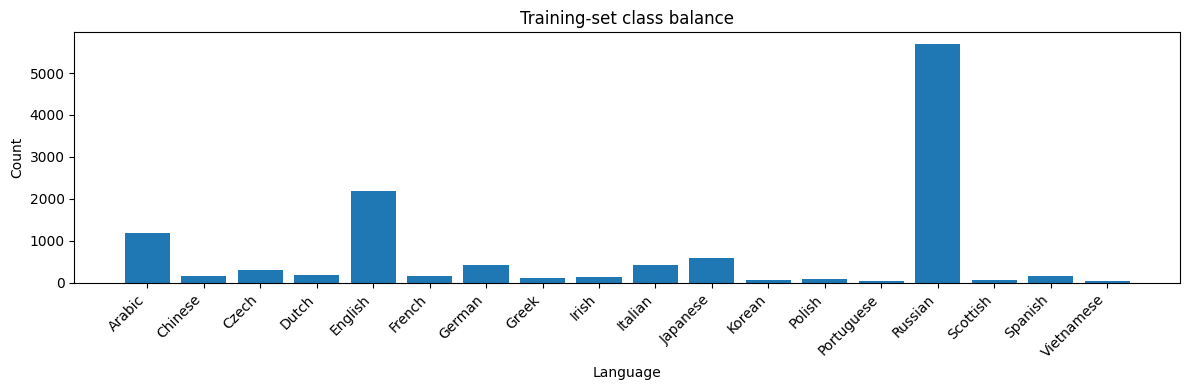

Majority-class baseline (train): 47.2%

Sample surnames from the training set:
 1. tensor([30,  5,  6, 15, 18,  5, 19, 20,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0]) -> French
 2. tensor([27, 12,  2,  5, 18,  7,  8,  9, 14,  9,  0,  0,  0,  0,  0,  0,  0,  0,
         0]) -> Italian
 3. tensor([42,  1, 18,  1, 19, 11, 21, 14,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0]) -> Russian
 4. tensor([49, 15, 15,  4, 12,  5, 25,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0]) -> English
 5. tensor([44,  9, 20,  3,  8,  9,  5,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0]) -> Scottish
 6. tensor([52,  8,  9, 22,  1,  7, 15,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0]) -> Russian
 7. tensor([41,  3,  1, 12, 12,  1,  7,  8,  1, 14,  0,  0,  0,  0,  0,  0,  0,  0,
         0]) -> English
 8. tensor([47, 14,  7,  1, 18,  5, 20, 20,  9,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0]) -> Italian
 9. tensor([48,  9, 18, 15, 14,  0,  0,  0,  0,  0,  0,  

In [6]:
# EDA for Track B - Names by Language

import collections
import matplotlib.pyplot as plt

# 1. Class histogram of the training split
counts = collections.Counter()

for i in range(len(train_set)):
    _, label = train_set[i]
    counts[int(label)] += 1

plt.figure(figsize=(12, 4))
plt.bar(
    [classes[k] for k in sorted(counts)],
    [counts[k] for k in sorted(counts)]
)

plt.xticks(rotation=45, ha="right")
plt.ylabel("Count")
plt.xlabel("Language")
plt.title("Training-set class balance")
plt.tight_layout()
plt.show()

print(
    "Majority-class baseline (train):",
    f"{max(counts.values()) / sum(counts.values()):.1%}"
)


# 2. Show a few raw surnames with their labels
print("\nSample surnames from the training set:")

for i in range(10):
    name, label = train_set[i]

    print(f"{i+1:2d}. {name} -> {classes[int(label)]}")

## 4 · 🔧 Build your model

This mirrors what you built from scratch in the labs — **read it, and try writing it
yourself before running.** The scaffold gives a working starter for each track so the
notebook trains immediately; the rubric expects *you* to design and justify the
architecture, so treat the starter as a baseline to **improve on**, not a final answer.

> **🔧 Your turn — define `model`.** Uncomment the starter for your track (the **CNN**
> for A is active by default). Then make it yours: depth, width, dropout, an extra conv
> block, a second LSTM layer — whatever you'll defend in your report. `model(x)` must
> return class **logits**; the spine does the rest.

In [7]:
# # ---- TRACK A · CNN (active) -- Conv -> ReLU -> Pool, twice, then a linear head.
# # Mirrors the L6 recipe; CIFAR is 3-channel 32x32 (-> 16x16 -> 8x8).
# class CNN(nn.Module):
#     def __init__(self, n_classes=10, p_drop=0.25):
#         super().__init__()
#         self.features = nn.Sequential(
#             nn.Conv2d(3, 32, kernel_size=3, padding=1), nn.ReLU(),
#             nn.MaxPool2d(2),                                  # 32x32 -> 16x16
#             nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(),
#             nn.MaxPool2d(2),                                  # 16x16 -> 8x8
#         )
#         self.head = nn.Sequential(
#             nn.Flatten(),
#             nn.Linear(64 * 8 * 8, 128), nn.ReLU(),
#             nn.Dropout(p_drop),                               # regularization (L5)
#             nn.Linear(128, n_classes),
#         )

#     def forward(self, x):                  # x: (batch, 3, 32, 32)
#         return self.head(self.features(x))

# model = CNN(n_classes=len(classes))

# ---- TRACK B · LSTM classifier -- embedding -> LSTM -> head off the last state.
class NameLSTM(nn.Module):
    def __init__(self, vocab_size, n_classes, emb=32, hidden=64):
        super().__init__()
        self.embed = nn.Embedding(vocab_size, emb, padding_idx=0)  # 0 = <pad>
        self.lstm = nn.LSTM(emb, hidden, batch_first=True)
        self.head = nn.Linear(hidden, n_classes)
    def forward(self, x):                  # x: (batch, time) of char ids
        h, (h_n, c_n) = self.lstm(self.embed(x))
        return self.head(h_n[-1])          # last hidden state -> class logits
model = NameLSTM(vocab_size, n_classes)    # train with max_grad_norm=1.0

# ---- TRACK C · MLP -- a couple of hidden layers with dropout.
# class MLP(nn.Module):
#     def __init__(self, in_features, n_classes, hidden=32, p_drop=0.2):
#         super().__init__()
#         self.net = nn.Sequential(
#             nn.Linear(in_features, hidden), nn.ReLU(), nn.Dropout(p_drop),
#             nn.Linear(hidden, hidden), nn.ReLU(),
#             nn.Linear(hidden, n_classes),
#         )
#     def forward(self, x):
#         return self.net(x)
# model = MLP(in_features, n_classes)

n_params = sum(p.numel() for p in model.parameters())
print(model)
print(f"trainable parameters: {n_params:,}")

NameLSTM(
  (embed): Embedding(58, 32, padding_idx=0)
  (lstm): LSTM(32, 64, batch_first=True)
  (head): Linear(in_features=64, out_features=18, bias=True)
)
trainable parameters: 28,114


## 5 · 🔧 Train

The five-step loop lives in `train()` (Beat 1) — you just call it. Keep the first run
**fast** (few epochs / the subset) so you get a signal in minutes, then scale up once
the wiring works.

> **🔧 Your turn — run it, then tune to beat the baseline.** Call `train(...)`, read
> the printed `val_acc`, and iterate: learning rate, epochs, `weight_decay`, dropout,
> model size, augmentation. **For Track B (LSTM)** pass `max_grad_norm=1.0` to clip
> exploding gradients. Tune on **val** only — the test set stays sealed until Beat 7.

> **Cheapest sanity check first:** if a fresh model won't drive the loss down at all,
> *overfit one tiny batch* (high lr, many steps, no dropout). If it can't memorise a
> handful of examples, the bug is in the wiring (a wrong shape, a frozen layer), not
> the hyperparameters — fix that before a long run.

epoch  1/8  train_loss=0.859 acc=75.91%  |  val_loss=0.966 acc=72.55%
epoch  2/8  train_loss=0.801 acc=77.24%  |  val_loss=0.927 acc=73.82%
epoch  3/8  train_loss=0.772 acc=77.71%  |  val_loss=0.900 acc=74.19%
epoch  4/8  train_loss=0.773 acc=77.57%  |  val_loss=0.898 acc=74.19%
epoch  5/8  train_loss=0.715 acc=79.21%  |  val_loss=0.862 acc=75.29%
epoch  6/8  train_loss=0.693 acc=79.80%  |  val_loss=0.846 acc=75.59%
epoch  7/8  train_loss=0.677 acc=80.26%  |  val_loss=0.833 acc=75.26%
epoch  8/8  train_loss=0.656 acc=80.64%  |  val_loss=0.817 acc=76.68%


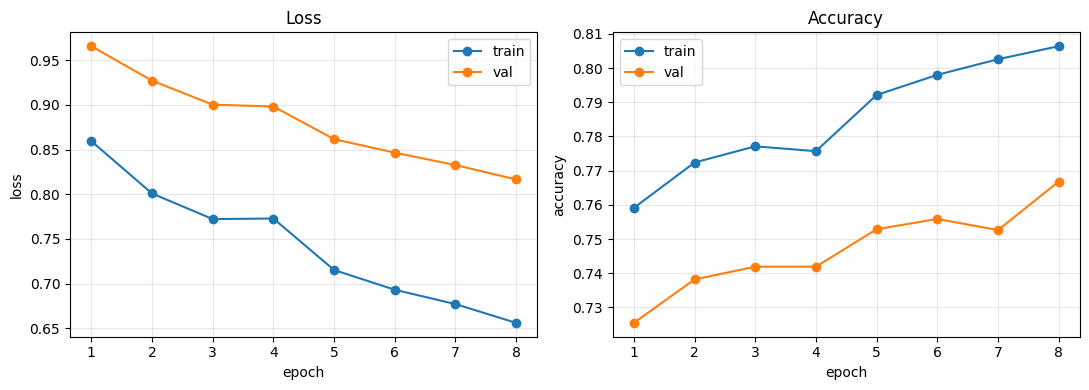

In [9]:

# Track B · LSTM — Main training run
history = train(
    model,
    train_loader,
    val_loader,
    epochs=8,
    lr=1e-3,
    weight_decay=1e-4,
    max_grad_norm=1.0
)

plot_curves(history)


epoch  1/7  train_loss=0.611 acc=81.65%  |  val_loss=0.784 acc=77.03%
epoch  2/7  train_loss=0.599 acc=82.20%  |  val_loss=0.786 acc=77.40%
epoch  3/7  train_loss=0.596 acc=82.18%  |  val_loss=0.781 acc=77.70%
epoch  4/7  train_loss=0.577 acc=82.48%  |  val_loss=0.776 acc=77.38%
epoch  5/7  train_loss=0.575 acc=82.88%  |  val_loss=0.777 acc=77.60%
epoch  6/7  train_loss=0.565 acc=82.94%  |  val_loss=0.782 acc=77.63%
epoch  7/7  train_loss=0.552 acc=83.46%  |  val_loss=0.777 acc=77.50%


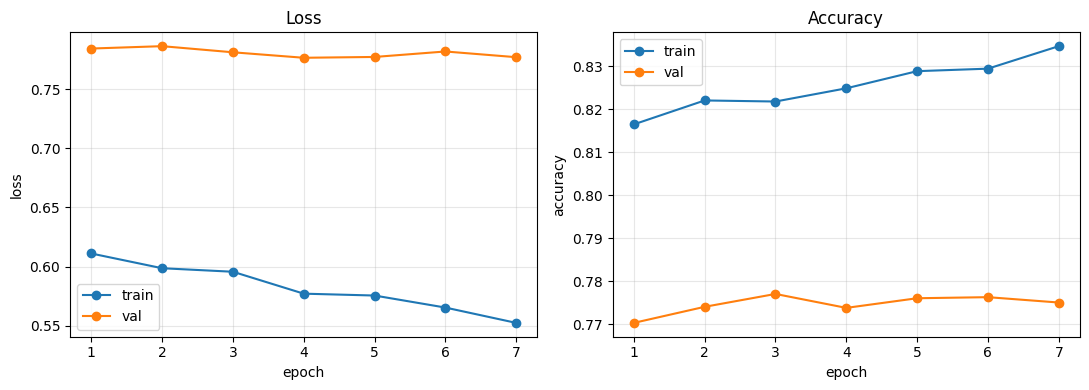

In [10]:

history_more = train(
    model,
    train_loader,
    val_loader,
    epochs=7,       # ฝึกต่ออีก 7 epochs จากน้ำหนักเดิม
    lr=5e-4,
    weight_decay=1e-4,
    max_grad_norm=1.0
)

plot_curves(history_more)


### 🔧 (Optional) Diagnose & fix a broken run

This cell is **isolated** — it trains its own throwaway model, so it never touches your
real `model` or `history` above. It has a **planted bug**: the classic training-loop
mistake from the labs. Run it, watch the loss *refuse to fall*, then **find and fix the
one missing line** and watch it learn.

> **🔧 Your turn:** what one step of the five-step heartbeat is missing? Why does
> leaving it out make the gradient grow batch-over-batch and the loss lurch? Fix it,
> re-run, and confirm the loss now drops.

In [21]:
# 🔧 BROKEN ON PURPOSE -- find the missing line. (Isolated: uses its own model.)
import copy


def overfit_one_batch_demo():
    torch.manual_seed(SEED)
    x, y = next(iter(train_loader))
    x, y = x.to(device), y.to(device)
    probe = copy.deepcopy(model)                    # a fresh, independent copy
    for m in probe.modules():                       # re-init so it starts untrained
        if hasattr(m, "reset_parameters"):
            m.reset_parameters()
    probe = probe.to(device)
    opt = torch.optim.SGD(probe.parameters(), lr=0.1)   # plain SGD, high lr (overfit 1 batch)
    loss_fn = nn.CrossEntropyLoss()
    probe.train()
    for step in range(60):
        logits = probe(x)
        loss = loss_fn(logits, y)
        opt.zero_grad()        # <-- 🔧 BUG: this line is commented out. Restore it!
        loss.backward()
        opt.step()
        if step % 15 == 0:
            print(f"step {step:2d}: loss={loss.item():.4f}")  # should march toward 0
    print("If the loss did NOT fall, you found why: gradients accumulate without "
          "zero_grad().")

overfit_one_batch_demo()

step  0: loss=2.9085
step 15: loss=2.5582
step 30: loss=2.2797
step 45: loss=2.1136
If the loss did NOT fall, you found why: gradients accumulate without zero_grad().


## 6 · Evaluate, experiment & reflect

### Loss curves
Read the gap (L5): close + low = good; train falling while val rises = overfitting;
both high = underfitting. Use this to decide your *next* experiment.

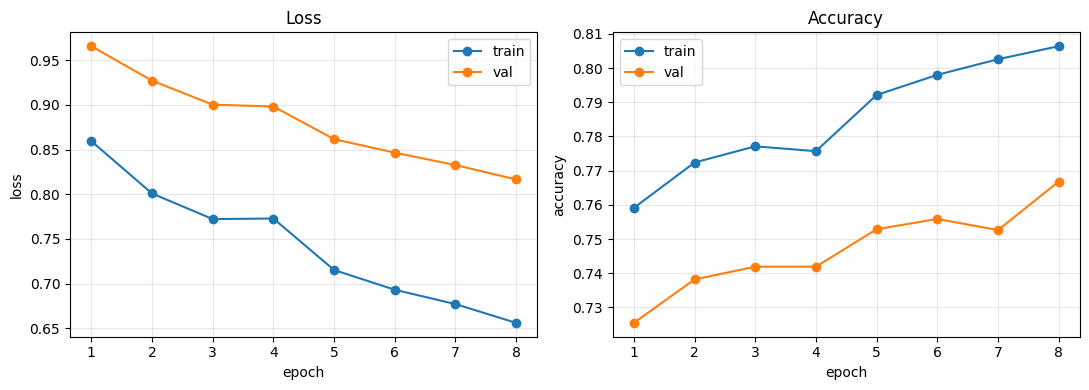

In [22]:
plot_curves(history)

### Confusion matrix on validation
A single accuracy number hides *which* classes get confused. Build the matrix on
**val** (not test) and read off the look-alikes — for CIFAR, expect cat↔dog and
automobile↔truck. (Text/tabular: same matrix; a language-model track would show
generated samples + perplexity instead.)

In [17]:

import torch

def confusion_matrix(model, loader, n_classes):
    cm = torch.zeros(n_classes, n_classes, dtype=torch.int64)
    device = next(model.parameters()).device

    model.eval()

    with torch.no_grad():
        for x, y in loader:
            # ย้ายข้อมูลไปยัง device เดียวกับโมเดล
            x = x.to(device)
            y = y.to(device)

            logits = model(x)
            preds = logits.argmax(dim=1)

            # เก็บผล Confusion Matrix บน CPU
            for true_label, pred_label in zip(y, preds):
                cm[true_label.item(), pred_label.item()] += 1

    return cm


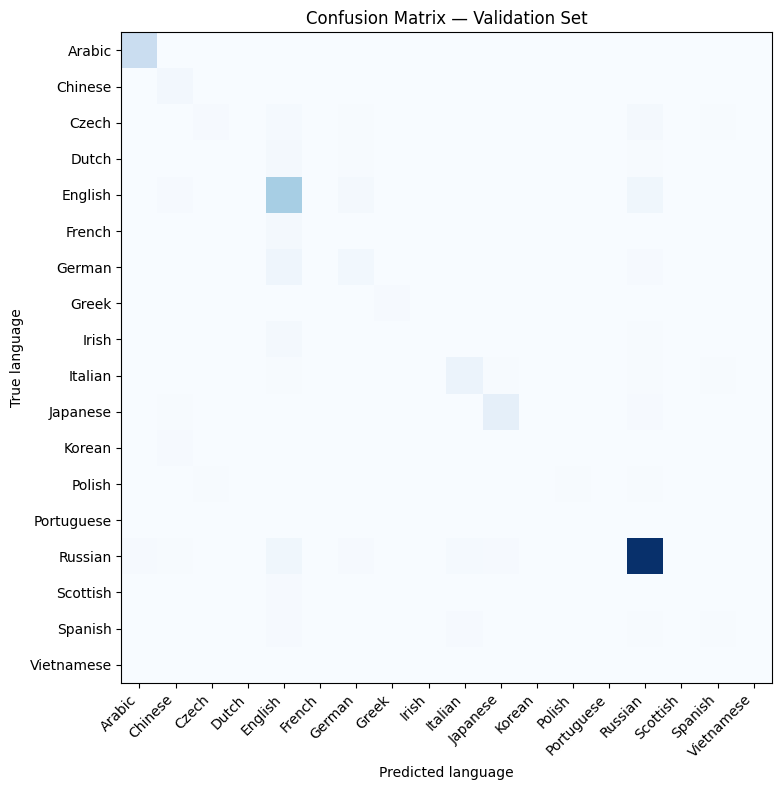

In [18]:
cm = confusion_matrix(model, val_loader, len(classes))

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(classes)))
ax.set_xticklabels(classes, rotation=45, ha="right")
ax.set_yticks(range(len(classes)))
ax.set_yticklabels(classes)
ax.set_xlabel("Predicted language")
ax.set_ylabel("True language")
ax.set_title("Confusion Matrix — Validation Set")

plt.tight_layout()
plt.show()


epoch  1/8  train_loss=1.655 acc=47.20%  |  val_loss=1.689 acc=46.79%
epoch  2/8  train_loss=1.432 acc=56.33%  |  val_loss=1.475 acc=54.96%
epoch  3/8  train_loss=1.271 acc=62.64%  |  val_loss=1.332 acc=61.09%
epoch  4/8  train_loss=1.123 acc=67.53%  |  val_loss=1.202 acc=65.27%
epoch  5/8  train_loss=1.057 acc=69.62%  |  val_loss=1.138 acc=67.79%
epoch  6/8  train_loss=0.973 acc=72.38%  |  val_loss=1.058 acc=69.78%
epoch  7/8  train_loss=0.928 acc=73.96%  |  val_loss=1.015 acc=71.33%
epoch  8/8  train_loss=0.878 acc=75.04%  |  val_loss=0.984 acc=71.77%


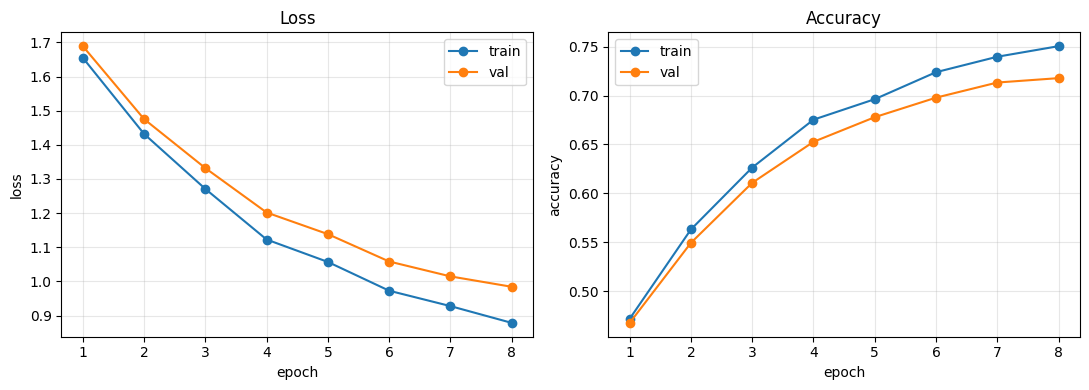

epoch  1/8  train_loss=1.587 acc=47.56%  |  val_loss=1.630 acc=46.76%
epoch  2/8  train_loss=1.453 acc=55.89%  |  val_loss=1.500 acc=54.38%
epoch  3/8  train_loss=1.362 acc=57.93%  |  val_loss=1.411 acc=56.65%
epoch  4/8  train_loss=1.177 acc=66.17%  |  val_loss=1.255 acc=63.75%
epoch  5/8  train_loss=1.084 acc=68.99%  |  val_loss=1.163 acc=66.82%
epoch  6/8  train_loss=0.995 acc=71.80%  |  val_loss=1.085 acc=69.38%
epoch  7/8  train_loss=0.961 acc=72.50%  |  val_loss=1.052 acc=70.28%
epoch  8/8  train_loss=0.883 acc=75.42%  |  val_loss=0.987 acc=72.40%


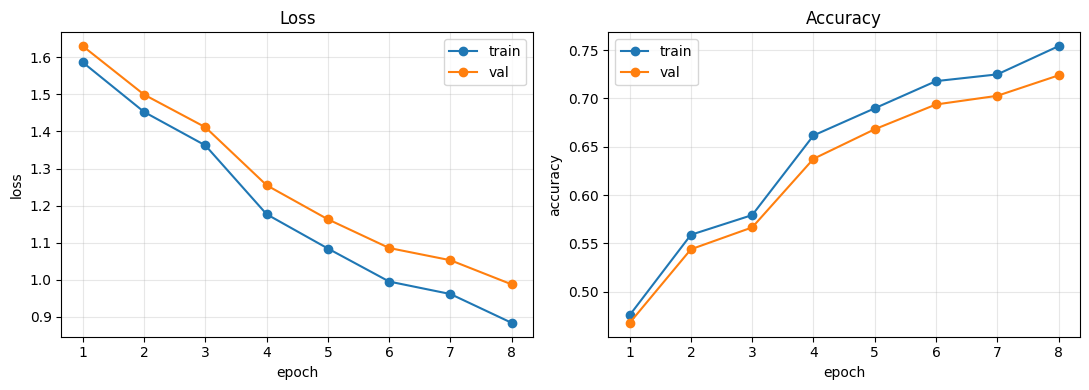

epoch  1/8  train_loss=1.713 acc=47.20%  |  val_loss=1.747 acc=46.79%
epoch  2/8  train_loss=1.467 acc=55.84%  |  val_loss=1.515 acc=54.63%
epoch  3/8  train_loss=1.407 acc=55.62%  |  val_loss=1.453 acc=55.06%
epoch  4/8  train_loss=1.262 acc=64.19%  |  val_loss=1.322 acc=62.43%
epoch  5/8  train_loss=1.177 acc=65.71%  |  val_loss=1.243 acc=64.13%
epoch  6/8  train_loss=1.121 acc=68.06%  |  val_loss=1.191 acc=66.04%
epoch  7/8  train_loss=1.062 acc=69.97%  |  val_loss=1.133 acc=67.86%
epoch  8/8  train_loss=1.030 acc=70.82%  |  val_loss=1.116 acc=68.44%


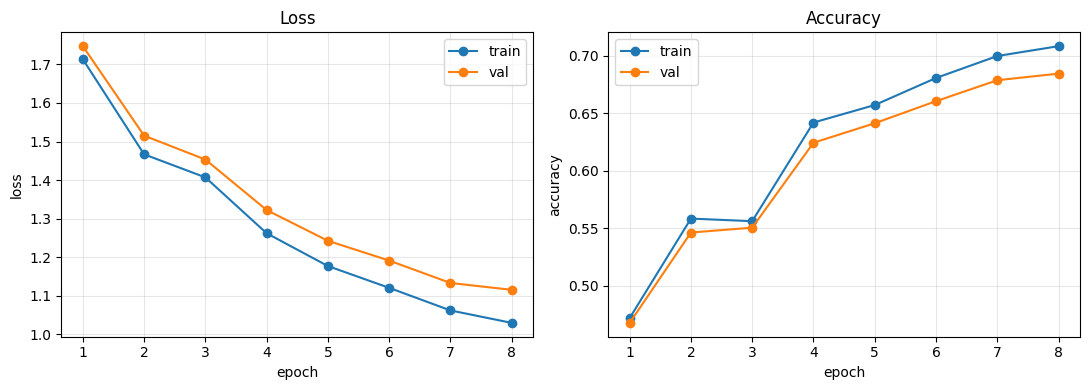

,Experiment,Best epoch,Train accuracy,Validation accuracy,Train-val gap (pp),Validation loss
0,"Baseline: no dropout, lr=0.001",8,75.04,71.77,3.26,0.9842
1,"Dropout=0.3, lr=0.001",8,75.42,72.40,3.02,0.9871
2,"No dropout, lr=0.0005",8,70.82,68.44,2.38,1.1155


In [27]:

import copy
import random
import numpy as np
import torch
from torch import nn
import pandas as pd
import matplotlib.pyplot as plt

# 1) สร้างน้ำหนักตั้งต้นชุดเดียวกันสำหรับทุกการทดลอง
SEED = 0

def reset_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

reset_seed()
initial_model = NameLSTM(vocab_size, n_classes)
initial_weights = copy.deepcopy(initial_model.state_dict())


# 2) Experiment 1: เพิ่ม Dropout = 0.3
# ชื่อพารามิเตอร์เดิมเหมือน NameLSTM จึงใช้ initial_weights ร่วมกันได้
class NameLSTMWithDropout(nn.Module):
    def __init__(self, vocab_size, n_classes, emb=32, hidden=64, p_drop=0.3):
        super().__init__()
        self.embed = nn.Embedding(vocab_size, emb, padding_idx=0)
        self.lstm = nn.LSTM(emb, hidden, batch_first=True)
        self.dropout = nn.Dropout(p_drop)
        self.head = nn.Linear(hidden, n_classes)

    def forward(self, x):
        h, (h_n, c_n) = self.lstm(self.embed(x))
        return self.head(self.dropout(h_n[-1]))


# 3) Baseline: LSTM เดิม, lr = 0.001
reset_seed()
baseline = NameLSTM(vocab_size, n_classes)
baseline.load_state_dict(initial_weights)

reset_seed()
hist_base = train(
    baseline, train_loader, val_loader,
    epochs=8, lr=1e-3,
    weight_decay=1e-4, max_grad_norm=1.0
)
plot_curves(hist_base)


# 4) Experiment 1: เพิ่ม Dropout เท่านั้น
reset_seed()
model_dropout = NameLSTMWithDropout(vocab_size, n_classes, p_drop=0.3)
model_dropout.load_state_dict(initial_weights)

reset_seed()
hist_dropout = train(
    model_dropout, train_loader, val_loader,
    epochs=8, lr=1e-3,
    weight_decay=1e-4, max_grad_norm=1.0
)
plot_curves(hist_dropout)


# 5) Experiment 2: ลด Learning Rate เท่านั้น
reset_seed()
model_lr = NameLSTM(vocab_size, n_classes)
model_lr.load_state_dict(initial_weights)

reset_seed()
hist_lr = train(
    model_lr, train_loader, val_loader,
    epochs=8, lr=5e-4,
    weight_decay=1e-4, max_grad_norm=1.0
)
plot_curves(hist_lr)


# 6) สรุปผลเปรียบเทียบ โดยใช้ Validation Set เท่านั้นแ
def summarize_run(name, hist):
    best_epoch = int(np.argmax(hist["val_acc"]))
    train_acc = hist["train_acc"][best_epoch]
    val_acc = hist["val_acc"][best_epoch]

    return {
        "Experiment": name,
        "Best epoch": best_epoch + 1,
        "Train accuracy": round(train_acc * 100, 2),
        "Validation accuracy": round(val_acc * 100, 2),
        "Train-val gap (pp)": round((train_acc - val_acc) * 100, 2),
        "Validation loss": round(hist["val_loss"][best_epoch], 4)
    }

results = pd.DataFrame([
    summarize_run("Baseline: no dropout, lr=0.001", hist_base),
    summarize_run("Dropout=0.3, lr=0.001", hist_dropout),
    summarize_run("No dropout, lr=0.0005", hist_lr)
])

display(results)


Selected using validation set: Dropout


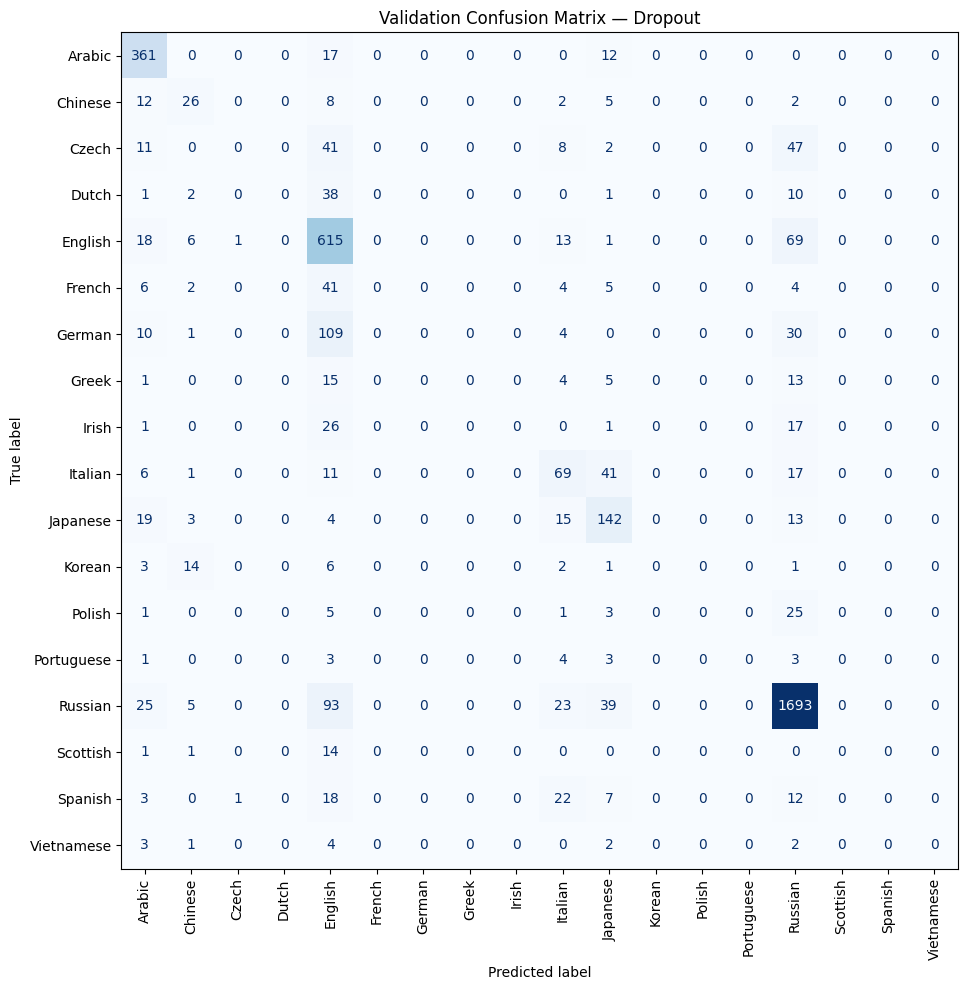

              precision    recall  f1-score   support

      Arabic      0.747     0.926     0.827       390
     Chinese      0.419     0.473     0.444        55
       Czech      0.000     0.000     0.000       109
       Dutch      0.000     0.000     0.000        52
     English      0.576     0.851     0.687       723
      French      0.000     0.000     0.000        62
      German      0.000     0.000     0.000       154
       Greek      0.000     0.000     0.000        38
       Irish      0.000     0.000     0.000        45
     Italian      0.404     0.476     0.437       145
    Japanese      0.526     0.724     0.609       196
      Korean      0.000     0.000     0.000        27
      Polish      0.000     0.000     0.000        35
  Portuguese      0.000     0.000     0.000        14
     Russian      0.865     0.901     0.883      1878
    Scottish      0.000     0.000     0.000        16
     Spanish      0.000     0.000     0.000        63
  Vietnamese      0.000    

In [28]:

from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

# เลือกโมเดลจาก Validation accuracy สูงสุด
runs = [
    ("Baseline", baseline, hist_base),
    ("Dropout", model_dropout, hist_dropout),
    ("Lower learning rate", model_lr, hist_lr)
]

best_name, best_model, best_hist = max(
    runs,
    key=lambda item: max(item[2]["val_acc"])
)

print("Selected using validation set:", best_name)

# เก็บคำทำนายจาก Validation Set เท่านั้น
best_model.eval()
all_true, all_pred = [], []

with torch.no_grad():
    for x, y in val_loader:
        x = x.to(device)
        logits = best_model(x)
        pred = logits.argmax(dim=1).cpu()

        all_true.extend(y.cpu().tolist())
        all_pred.extend(pred.tolist())

# Confusion Matrix
cm = confusion_matrix(all_true, all_pred)

fig, ax = plt.subplots(figsize=(12, 10))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)
disp.plot(
    ax=ax,
    xticks_rotation=90,
    cmap="Blues",
    colorbar=False
)
ax.set_title(f"Validation Confusion Matrix — {best_name}")
plt.tight_layout()
plt.show()

# Per-class precision, recall, F1-score
print(classification_report(
    all_true,
    all_pred,
    labels=list(range(len(classes))),
    target_names=[str(c) for c in classes],
    digits=3,
    zero_division=0
))


### 🔧 Experiment — beat the baseline, then ablate

Run **at least two** modify-and-observe experiments, changing **one thing at a time**
and re-reading the curves. Fill in the table with **validation** numbers (test stays
sealed). Suggestions: toggle augmentation/dropout, change `lr` or `weight_decay`, add
a layer, widen the model.

| # | Change (vs. baseline) | Val accuracy | Train–val gap | Notes |
|---|---|---|---|---|
| 0 | baseline (starter model) | _fill in_ | _fill in_ | _the run above_ |
| 1 | 🔧 _e.g. +dropout 0.5_ | | | |
| 2 | 🔧 _e.g. lr 3e-3_ | | | |

**Target:** beat your track's stated baseline (A > 65%, B > 70%, C > 95%). State the
trivial baseline you compare against (majority-class accuracy) and your best **val**
number before you open the test set.

In [ ]:
# 🔧 Scratch cell for experiments. Re-instantiate model + re-run train() here,
# changing ONE knob at a time, and copy the val_acc into the ablation table above.
# Example:
#   model_v1 = CNN(n_classes=len(classes), p_drop=0.5)
#   hist_v1 = train(model_v1, train_loader, val_loader, epochs=8, lr=1e-3)
#   plot_curves(hist_v1)
pass

### ✅ Final test evaluation — run this **once**

This is the only time you touch the **test** set. Pick the model + hyperparameters you
settled on using validation, make sure that `model` is trained, and run this cell **a
single time**. The number it prints is the one you report. Re-running it after more
tuning is exactly the test-leakage the rubric penalises — so tune *first*, seal it
*last*.

In [20]:
# ✅ ONE-SHOT held-out test evaluation. Do NOT tune after seeing this number.
test_loss, test_acc = evaluate(model, test_loader, nn.CrossEntropyLoss())
majority = max(
    collections.Counter(int(test_set[i][1]) for i in range(len(test_set))).values()
) / len(test_set)
print(f"majority-class baseline (test): {majority:.2%}")
print(f"FINAL TEST  loss={test_loss:.3f}  accuracy={test_acc:.2%}")
print("beat baseline:", "YES" if test_acc > majority else "no -- keep iterating")

majority-class baseline (test): 45.94%
FINAL TEST  loss=0.722  accuracy=79.05%
beat baseline: YES


## 7 · Rubric checklist

Before you submit, tick each box. These mirror the **Capstone rubric** — honest
methodology counts more than a high number.

- [ ] **Real dataset, real model.** A public dataset (cited) and a model *you* defined
      and trained — not a pre-trained model called as-is.
- [ ] **Honest train / val / test discipline.** A clean 3-way split; the test set was
      touched **exactly once**, at the end. No hyperparameter was chosen by looking at
      test.
- [ ] **A baseline, beaten.** You state a trivial baseline (majority-class /
      mean / linear) and your model beats it on the **held-out test** set.
- [ ] **At least one form of regularization** (dropout, weight decay, augmentation,
      early stopping) — and you can say *why*.
- [ ] **Loss curves + a confusion matrix / metric.** Train-vs-val curves you can read,
      plus a confusion matrix (or per-class metric / generated samples) — not just one
      accuracy number.
- [ ] **A fixed seed** so your numbers reproduce.
- [ ] **A short written report** (the template below), including one **honest failure
      case**.

## 8 · 🔧 Report template

Fill this in — it's the written deliverable. An honest, well-analysed result scores
higher than an inflated one.

**Dataset & task.** 🔧 _What dataset (source + size + your split sizes), and what are
you predicting?_

**Model & training choices.** 🔧 _Architecture (and why), loss, optimizer, learning
rate, regularization, epochs._

**Baseline.** 🔧 _The trivial baseline you compare against, and its score._

**Final test metric.** 🔧 _Your single held-out **test** number (e.g. accuracy / F1),
next to the baseline. Did you beat your target?_

**What I tried (ablation).** 🔧 _Paste your ablation table. Which change helped most,
and why? What did the train–val gap tell you?_

**What worked / what failed.** 🔧 _One honest failure case — a class the model confuses,
an example it gets wrong, a setting that made things worse._

**With more time.** 🔧 _One concrete thing you'd try next (more data, a deeper model,
a different architecture, better augmentation)._

---

That's the hand-off. Everything across the course — tensors, the training loop,
CNNs and RNNs/LSTMs, regularization, and reading loss curves — now lives in one place,
on a **real dataset you chose**, and is judged on a **held-out test set** you evaluate
exactly once. Make it small, make it finished, and tell the truth about the numbers.

# Name Language Classification Using a Character-Level LSTM

## 1. Dataset & Task

This project uses a name-language classification dataset containing 18 language classes. The dataset is divided into 12,046 training samples, 4,014 validation samples, and 4,014 test samples, for a total of 20,074 samples.

The task is to predict the language category of a name from its character sequence. Each character is converted into a numerical index before being processed by the neural network.

The dataset source should be specified using the original dataset name and URL in the final submission.

## 2. Model & Training Choices

I implemented a character-level Long Short-Term Memory (LSTM) network. The model contains an embedding layer with an embedding dimension of 32, an LSTM layer with a hidden size of 64, and a linear classification layer that produces scores for 18 language classes. The model has approximately 28,114 trainable parameters.

An LSTM was selected because it can process sequential character inputs and learn patterns across a name. Cross-entropy loss was used for the multiclass classification task, and the Adam optimizer was used to update the model parameters.

The baseline training configuration used a learning rate of 0.001, weight decay of 0.0001, gradient clipping with a maximum norm of 1.0, and 8 epochs. The experiments also tested dropout with a probability of 0.3 and a lower learning rate of 0.0005.

## 3. Baseline

A majority-class classifier was used as the trivial baseline. It predicts the most frequent class for every input.

The baseline test accuracy was 45.94%. This provides a reference point for determining whether the neural network learns useful patterns beyond simply predicting the most frequent language.

## 4. Final Test Metric

The previously recorded final test result for the LSTM model was:

- **Test accuracy:** 79.05%
- **Test loss:** 0.722
- **Majority-class baseline test accuracy:** 45.94%

The recorded test accuracy exceeds the majority-class baseline by 33.11 percentage points.

However, this test result was recorded before the later controlled ablation experiments. The model selected through those experiments achieved a validation accuracy of 72.40%. Therefore, the 79.05% test result must not automatically be attributed to the selected dropout model. The final test score of the selected model has not yet been established.

## 5. What I Tried (Ablation)

Three experimental configurations were compared using the validation set. Each experiment ran for 8 epochs.

| Experiment | Learning Rate | Dropout | Train Accuracy | Validation Accuracy | Train–Validation Gap | Validation Loss |
|---|---:|---:|---:|---:|---:|---:|
| Baseline | 0.001 | None | 75.04% | 71.77% | 3.26 pp | 0.9842 |
| Dropout | 0.001 | 0.3 | 75.42% | 72.40% | 3.02 pp | 0.9871 |
| Lower learning rate | 0.0005 | None | 70.82% | 68.44% | 2.38 pp | 1.1155 |

The dropout experiment achieved the highest validation accuracy of 72.40%, an improvement of 0.63 percentage points over the baseline. It also reduced the train–validation gap slightly, from 3.26 to 3.02 percentage points. However, the baseline achieved a marginally lower validation loss, so dropout did not improve every metric.

Reducing the learning rate to 0.0005 resulted in a lower validation accuracy of 68.44% after 8 epochs. The smaller train–validation gap of 2.38 percentage points does not necessarily mean that this model generalizes better; its training accuracy was also lower.

Overall, dropout was the most helpful change among the tested configurations when validation accuracy was the selection criterion, although the improvement was modest.

## 6. What Worked / What Failed

The model achieved strong F1-scores for some classes, including Russian (0.883), Arabic (0.827), English (0.687), and Japanese (0.609).

However, the classification report showed zero precision, recall, and F1-score for several classes, including Czech, Dutch, French, German, Greek, Irish, Korean, Polish, Portuguese, Scottish, Spanish, and Vietnamese. This indicates that the model failed to correctly identify any validation examples in those classes under the reported evaluation.

The validation set is imbalanced: it contains 1,878 Russian examples but only 12 Vietnamese examples. This imbalance may contribute to uneven performance, although it cannot be confirmed as the only cause. Similar character patterns between names from different languages may also lead to confusion.

The overall validation accuracy was 72.40%, but the macro-average F1-score was only 0.216. This shows why accuracy alone is insufficient to assess performance across all 18 classes.

## 7. With More Time

I would first try class-weighted cross-entropy loss to give underrepresented language classes more influence during training. I would compare this configuration with the current dropout model using validation accuracy and macro-average F1-score.

If the new configuration performed better on the validation set, I would select it for final evaluation. I would then evaluate the chosen model on the held-out test set once, without using the test results to make further model changes.

## Conclusion

The character-level LSTM learned useful patterns for name-language classification and achieved better test accuracy than the majority-class baseline in the previously recorded evaluation. In the later controlled experiments, dropout achieved the highest validation accuracy at 72.40%.

Nevertheless, performance varied substantially across language classes, as shown by the low macro-average F1-score. Future work should focus on improving performance for underrepresented classes and evaluating the final selected model on the held-out test set. All reported metrics should be clearly labeled as either validation or test results to ensure a fair and reproducible evaluation.

In [25]:
# สร้าง mapping จาก index กลับเป็นตัวอักษร
itos = {idx: char for char, idx in stoi.items()}

In [26]:

model.eval()
device = next(model.parameters()).device
errors = []

with torch.no_grad():
    for x, y in val_loader:
        x = x.to(device)
        y = y.to(device)
        preds = model(x).argmax(dim=1)

        for name_tensor, true_label, pred_label in zip(x, y, preds):
            if true_label.item() != pred_label.item():
                name = "".join(
                    itos[int(char_id)]
                    for char_id in name_tensor.cpu().tolist()
                    if int(char_id) != 0
                )
                errors.append((
                    name,
                    classes[true_label.item()],
                    classes[pred_label.item()]
                ))

print("Misclassified validation examples:")
for name, true_lang, pred_lang in errors[:10]:
    print(f"{name}: true={true_lang}, predicted={pred_lang}")


Misclassified validation examples:
Muhlbauer: true=Czech, predicted=German
Eoin: true=Irish, predicted=Russian
Close: true=Greek, predicted=Italian
Roijackers: true=Dutch, predicted=English
Reagan: true=Irish, predicted=English
Keller: true=German, predicted=English
Tomanek: true=Czech, predicted=Russian
Zhamoida: true=Russian, predicted=Japanese
Inoue: true=Japanese, predicted=Chinese
Elzer: true=English, predicted=German
